# ACT DR6 results [Link](https://act.princeton.edu/act-dr6-data-products)

To install ACT maps [HERE LAMBDA](https://lambda.gsfc.nasa.gov/product/act/act_dr6.02/).

To do this you need some dependeces as [**pixell**](https://pixell.readthedocs.io/en/latest/), this one is very important to read, write and show ACT maps in CAR representation (Plate Carrée). Also, you can find [TUTORIALS](https://github.com/simonsobs/pixell_tutorials/).

Here we will plot some maps of ACT in CAR representation, and also observe differences between coadded maps used in [A Measurement of the DR6 CMB Lensing Power Spectrum and its Implications for Structure Growth](https://arxiv.org/abs/2304.05202v3) and compton-y map of [High-resolution component-separated maps across one-third of the sky](https://arxiv.org/abs/2307.01258v1) and their implications on delensing.



In [87]:
from pixell import enmap, utils, enplot, reproject, curvedsky
import numpy as np
import os
from pathlib import Path
import healpy as hp
import matplotlib.pyplot as plt


os.chdir("/home/jorge/Escritorio/Proy_cosmo/Cosmo_MSc")

In pixell, a maps is encapsulated in an `ndmap`, which combines two objects: a numpy array that correspond to two coordinate axes of the maps, and a `wcs` that especifies the World Coordinate Sistem. 

Also, the combination of wcs and the shape of the numpy array will be called the `geometry`, because they completely specifies the footprint of a map.

The `wcs` information describes the correspondence between celestial coordinates (RA: Right Ascension in Equatorial sistem) and the pixel indices in the two right-most axes.

## Reading a map from disk

To read a map in `FITS` we use `read_map` in the module `pixell.enmap`. This module contains the majority of map manipulation functions. 

In [2]:
# Compton-y maps  "ACT_maps/act-planck_dr6.02_nilc_ComptonY.fits"

# coadded maps  "ACT_maps/act_dr6.02_coadd_AA_night_f090_map.fits"

imap = enmap.read_map("ACT_maps/act_dr6.02_coadd_AA_night_f090_map.fits")

# when shape is (3, ... , ...) we have I, Q and U maps
print(imap.geometry, imap.dtype)

((3, 10320, 43200), car:{cdelt:[-0.008333,0.008333],crval:[0,0],crpix:[21601.00,7560.50]}) float32


Alternatively, one can select a rectangular region.

In [3]:
# Dec is vertical -90 to 90
# Ra is horizontal 0 to 360

dec_min = -7 ; ra_min = 5 ; dec_max = 3 ; ra_max = -5

# All coordinates in pixell are specified in radians
box = np.array([[dec_min, ra_min], [dec_max, ra_max]]) * utils.degree

# Compton-y maps  "ACT_maps/act-planck_dr6.02_nilc_ComptonY.fits"

# coadded maps  "ACT_maps/act_dr6.02_coadd_AA_night_f090_map.fits"

imap_box = enmap.read_map("ACT_maps/act_dr6.02_coadd_AA_night_f090_map.fits", box=box)

## Visualizing maps

We can use `pixell.enplot` functions to visualize ndmaps. First, we create the plot and then show it.

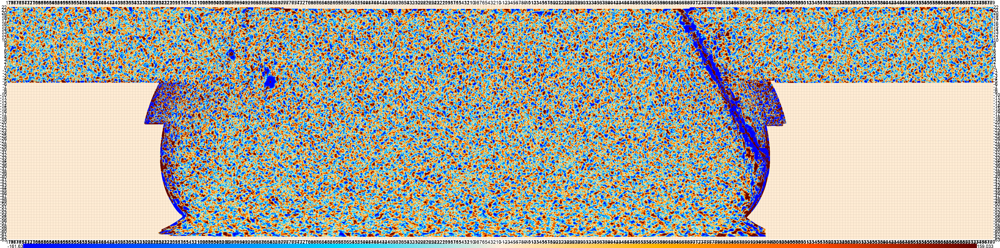

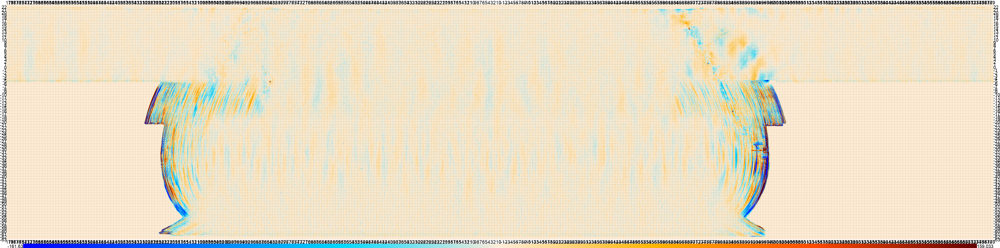

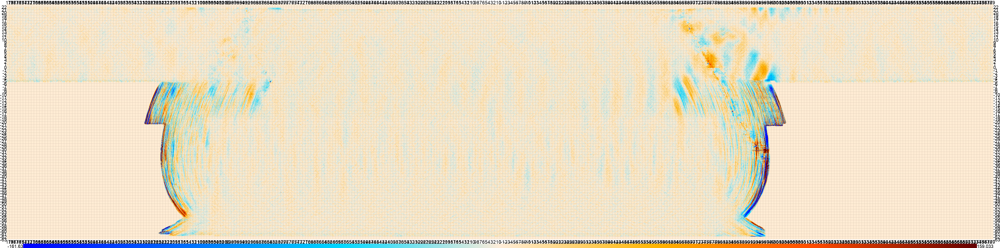

In [4]:
# Plot imap

enplot.pshow(imap, colorbar=True, downgrade=10)

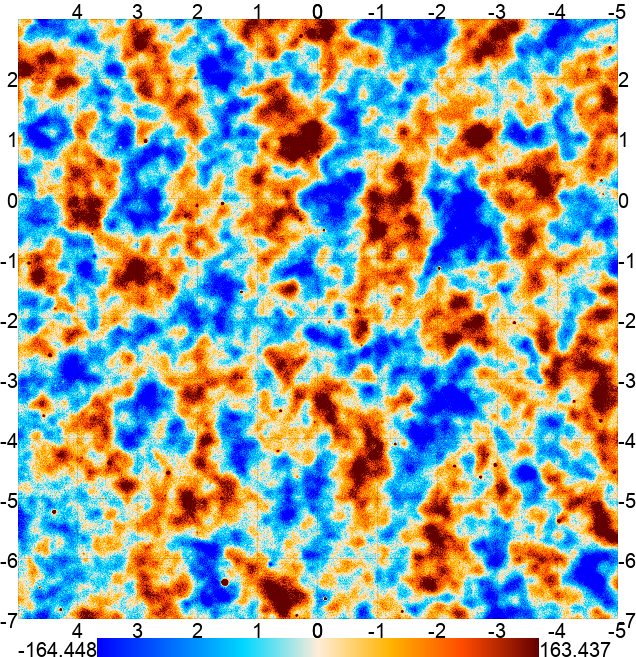

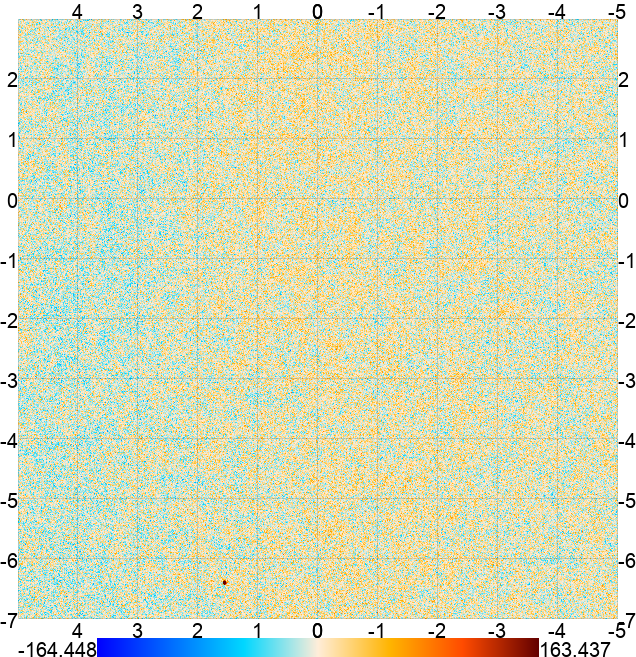

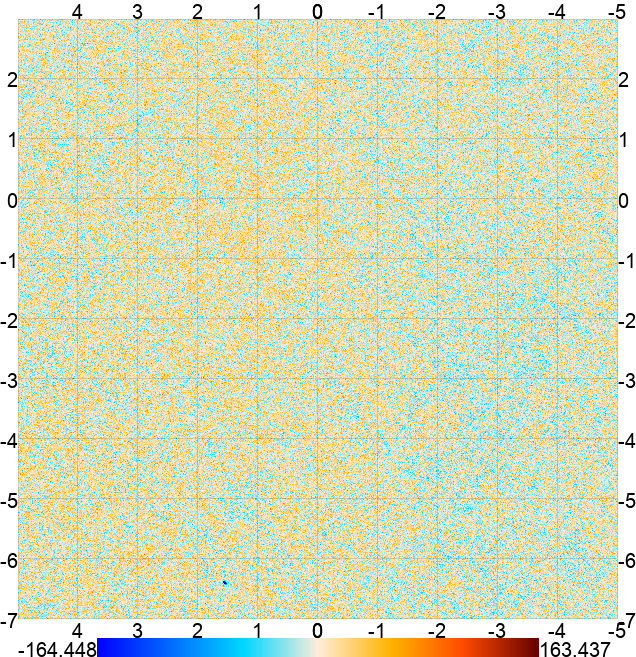

In [5]:
# Plot imap_box

enplot.pshow(imap_box, colorbar=True, downgrade=2)

## Spherical Harmonic with pixell

Let's see how to filter the *alm* and how to project the *alm* back to the map space.

If the map have a shape like (3, Ny, Nx), then the output shape will be  (3, nalm).

In [7]:
# The transformation is limited by the `lmax` factor.
lmax = 3000

alms = curvedsky.map2alm(imap, lmax=lmax)


**IMPORTANT**

The SHT is not fully information preserving. Let's see if we use $\ell_{max} = 3000$ we are ignoring small scales, the effect in our map will be **ringing** around bright point sources (in fact, point sources have signal at small scales).

If we want to visualize the $E$ and $B$ maps, rather than $Q$ and $U$, we first need to do map2alm with the default spin=[0,2] and then alm2map with a spin-0 transform

In [8]:
# IMPORTANT

# Maybe you have noticed, it is necessary to include a map.copy() this is just to return the same map distribution. 

IEBmap = curvedsky.alm2map(alms, imap.copy(), spin=[0,0]) # specify "0" for the Q, U components now

Also, you can apply a filter `fl` using `curvedsky.almxfl`

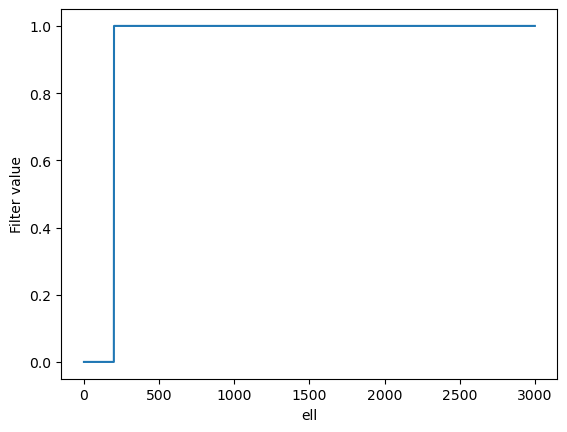

In [9]:
# Lets start by creating a filter
fl = np.ones(lmax+1) # l=0 is one of the ells!
fl[:200] = 0         # cut out large scales

# Let's plot the filter.
plt.plot(fl)
plt.ylabel("Filter value")
plt.xlabel("ell")
plt.show()

In [10]:
# Let's apply the filter
alms = curvedsky.map2alm(imap_box[0], lmax=lmax)
filtered_alms = curvedsky.almxfl(alms, fl)

# We can also try filtering out the small scales for comparison
fl = np.ones(lmax + 1)
fl[200:] = 0

filtered_alms_small_scales = curvedsky.almxfl(alms, fl)

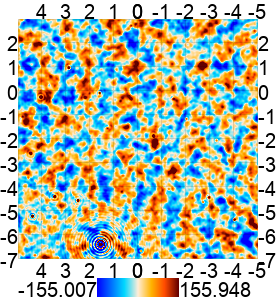

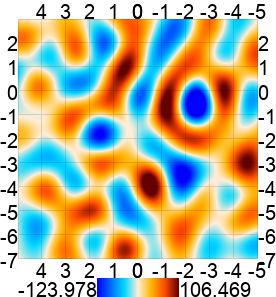

In [11]:
# We can then project the filtered alms to map space and take a look at the resulting map
filtered_map = curvedsky.alm2map(filtered_alms, imap_box[0].copy())
filtered_map_small_scales = curvedsky.alm2map(filtered_alms_small_scales, imap_box[0].copy())
enplot.pshow(filtered_map, downgrade=5, colorbar=True)
enplot.pshow(filtered_map_small_scales, downgrade=5, colorbar=True)


Here we can see that in the first map the large scale modes are no visible. On the other hand, the second map shows just small scale modes.

## Calculate power spectrum

To do this, we use `curvedsky.alm2cl`, but there are more tutorials available on [DR4_DR5_Notebooks](https://github.com/ACTCollaboration/DR4_DR5_Notebooks/tree/master/Notebooks).

Also, we still want to apodize the map edges to avoid discontinuities `enmap.apod` will be usefull for this.



(3, 3001)


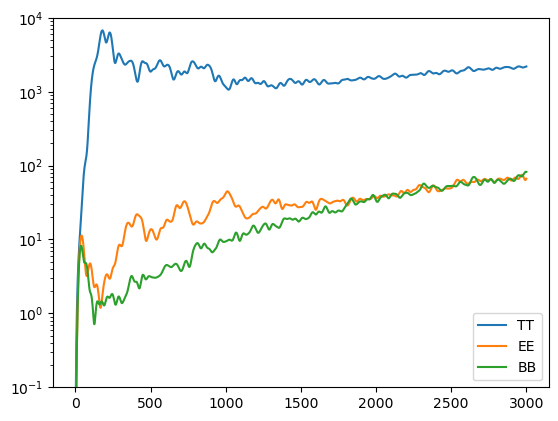

In [12]:
# get an apodized mask, multiply the map before doing masp2alm
apod_mask = enmap.apod(enmap.ones(imap_box[0].shape, imap_box[0].wcs), width=100)

alms_apod = curvedsky.map2alm(apod_mask * imap_box, lmax=lmax)

# get the correction factor that accounts for the power lost due to observe just a fraction of the sky
# enmap.pixsizemap is a map of all the physical pixel areas in steradians
w2 = np.sum(apod_mask.pixsizemap() * apod_mask**2) / (4*np.pi)

# compute the spectra
cl = curvedsky.alm2cl(alms_apod) / w2

print(cl.shape)

# we can plot it 

l = np.arange(cl.shape[1])

for i in range(3):
  plt.semilogy(l, cl[i] * l *(l+1) / 2 / np.pi, label=['TT', 'EE', 'BB'][i])
plt.ylim(1e-1, 1e4)
plt.legend()

(3, 3, 3001)


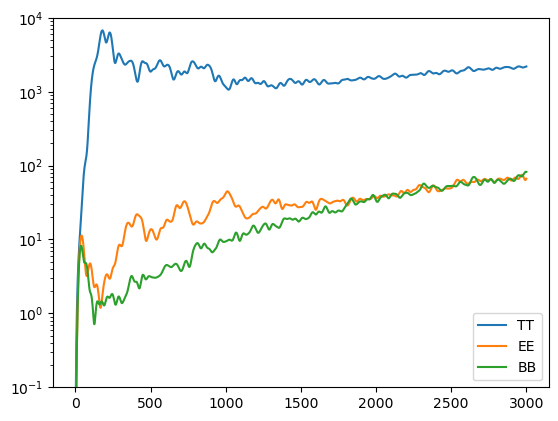

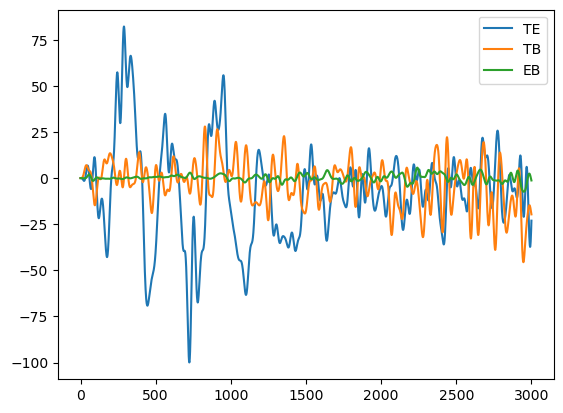

In [13]:
# By default, alm2cl get the autospectrum. But we can also pass a second alm

clx = curvedsky.alm2cl(alms_apod[:, None], alms_apod[None, :]) / w2

print(clx.shape)

# plot
for i in range(3):
  plt.semilogy(l, clx[i, i] * l *(l+1) / 2 / np.pi, label=['TT', 'EE', 'BB'][i])
plt.ylim(1e-1, 1e4)
plt.legend()
plt.show()

for i in range(3):
  for j in range(i + 1, 3):
    plt.plot(l, clx[i, j] * l *(l+1) / 2 / np.pi, label='TEB'[i] + 'TEB'[j])
plt.legend()
plt.show()

A real cosmological analysis would need to use a *mode coupling matrix*, not the simple `w2` factor.

## Using Healpy with alms

alms don't know anything about map pixelization that produced them. So they are a way of translating between different pixelization schemes (but with a bandlimit set by `lmax`)

## Projecting to Healpix

We can use `reproject.map2healpix`, with optional rotation coordenates. 


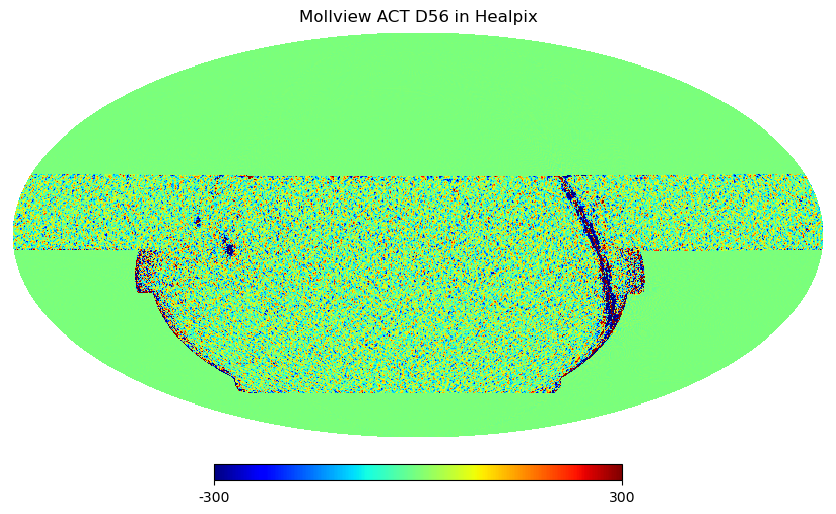

In [ ]:
from matplotlib import cm

# reproject the ACT map to healpix map
nside = 2048
lmax = 3000

map_hp = reproject.map2healpix(imap, nside=nside, lmax=lmax)

hp.mollview(map_hp[0], title= "Mollview ACT D6 in Healpix", min = -300, max = 300, cmap ="jet")

### Esto estara bien?? Ver coordenadas en la que esta incluso buscar la mascara que se utilizo ya que esto sería el mapa completo...
   

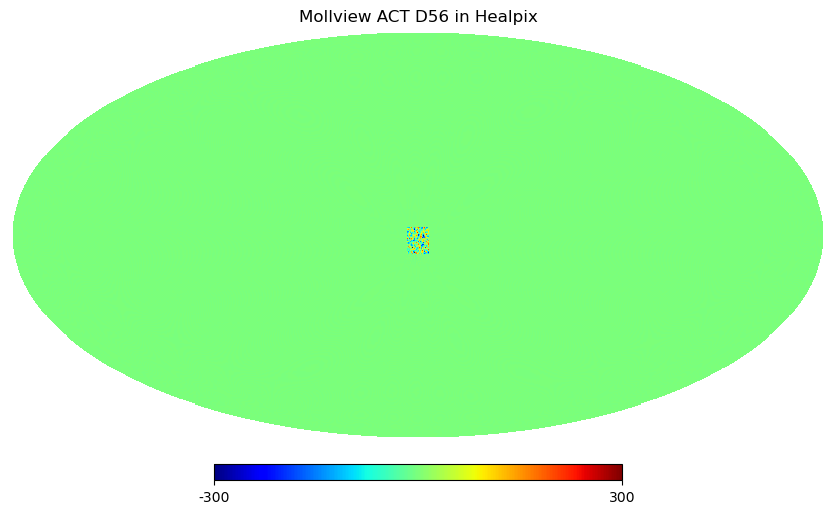

In [19]:
# reproject the ACT map to healpix map
nside = 2048
lmax = 3000

map_hp_box = reproject.map2healpix(imap_box, nside=nside, lmax=lmax)

hp.mollview(map_hp_box[0], title= "Mollview ACT D56 in Healpix", min = -300, max = 300, cmap ="jet")

## Correlation of the ACT CMB Lensing Map with Planck CIB map

Our lensing map is signal dominated and traces the dark matter distribution with high fidelity, we therefore expect it to be highly correlated with structures of LSS. One such tracer is the CIB, a faint glow of infrared radiation emitted by the stars from dusty forming galaxies.



In [88]:
## Load \kappa maps  (in Equatorial coordinates)

kappa_alm = hp.read_alm("ACT_maps/potencial lensing/dr6_lensing_release/maps/baseline/kappa_alm_data_act_dr6_lensing_v1_baseline.fits")

mask_kappa = hp.read_map("ACT_maps/potencial lensing/dr6_lensing_release/maps/baseline/mask_act_dr6_lensing_v1_healpix_nside_4096_baseline.fits")

ell_0, Nl_kk = np.loadtxt("ACT_maps/potencial lensing/dr6_lensing_release/maps/baseline/N_L_kk_act_dr6_lensing_v1_baseline.txt", unpack=True)

# Filter is just 0 and 1 in ells
ell_1, filter_kk = np.loadtxt("ACT_maps/potencial lensing/dr6_lensing_release/maps/baseline/kappa_filter_act_dr6_lensing_v1_baseline.txt", unpack=True)

## Theory Cl_kk
theory_cl_kk = np.loadtxt("ACT_maps/potencial lensing/dr6_lensing_release/maps/baseline/theory_cl_kk.txt")


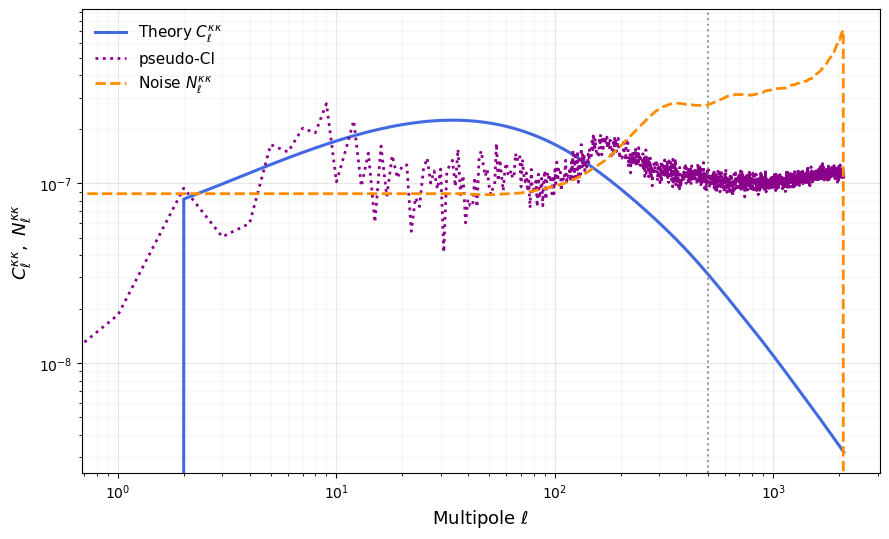

In [89]:
# Convert any nans to avoid problems later on
kappa_alm = np.nan_to_num(kappa_alm).astype(np.complex128)

obs_clkk = hp.alm2cl(kappa_alm, lmax=2100)

plt.figure(figsize=(9, 5.5))

# Espectro teórico
plt.plot( ell_0, theory_cl_kk[:2101], color="royalblue", linewidth=2.2, label=r"Theory $C_\ell^{\kappa\kappa}$")

# Espectro de pseudo-cl kk
plt.plot( ell_0, obs_clkk, color="darkmagenta", linewidth=2, linestyle="dotted", label=r"pseudo-Cl")

# Espectro de ruido
plt.plot( ell_0, Nl_kk, color="darkorange", linewidth=2, linestyle="--", label=r"Noise $N_\ell^{\kappa\kappa}$")

# Escala logarítmica en ambos ejes
plt.xscale("log")
plt.yscale("log")

# Línea de referencia en ell = 500
plt.axvline( x=500, color="gray", linestyle=":", linewidth=1.5, alpha=0.8
)

plt.xlabel(r"Multipole $\ell$", fontsize=13)
plt.ylabel(r"$C_\ell^{\kappa\kappa},\ N_\ell^{\kappa\kappa}$", fontsize=13)

# Cuadrícula suave
plt.grid(True, which="major", alpha=0.3)
plt.grid(True, which="minor", alpha=0.1)

plt.legend(fontsize=11, frameon=False)

# Mejorar distribución
plt.tight_layout()

plt.show()

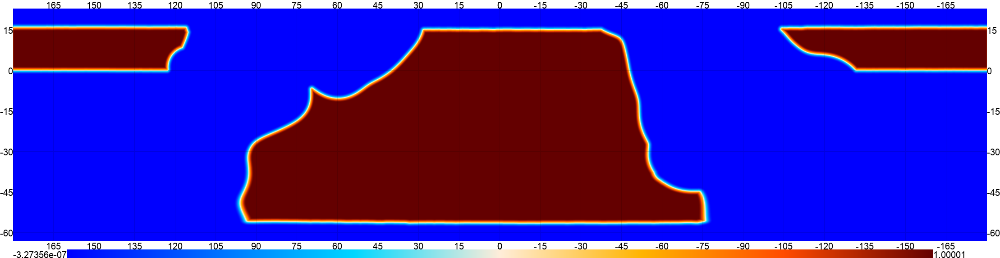

In [90]:
## MASK in healpy project to CAR

box = np.array([[-63,180],[23,-180]]) * utils.degree

shape, wcs = enmap.geometry(pos=box, res=1 * utils.arcmin, proj='car')

mask = reproject.healpix2map(mask_kappa, shape, wcs)

plot = enplot.get_plots(mask, downgrade=10, colorbar=True, ticks=15)
enplot.show(plot, method="ipython")

/tmp/ipykernel_8518/1448397965.py:7: RuntimeWarning: invalid value encountered in divide
  filter = np.nan_to_num(2*theory_cl_kk[:2101]/(theory_cl_kk[:2101] + Nl_kk)/ell_0**2)


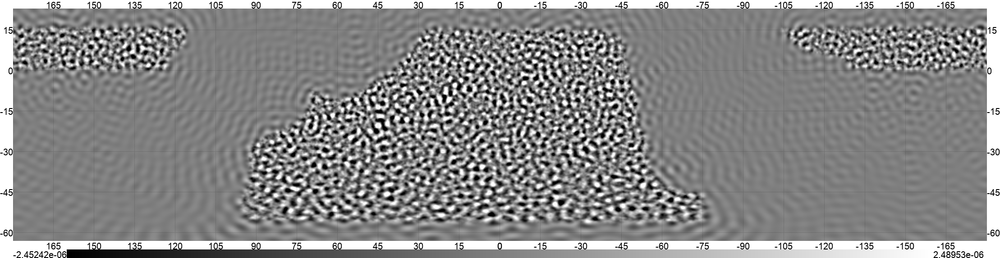

In [91]:
# Convert any nans to avoid problems later on
kappa_alm = np.nan_to_num(kappa_alm)

## Diagonal Wiener filter + \kappa to \phi
# \phi = \kappa * 2/(\ell * (\ell + 1)) 

filter = np.nan_to_num(2*theory_cl_kk[:2101]/(theory_cl_kk[:2101] + Nl_kk)/ell_0**2)

filter[ell_0<100] = 0

# We can now filter the kappa alms by the filter produced above
filter_kappa = hp.almxfl(kappa_alm, filter)

# We now convert the filtered alms to map space
frmap = curvedsky.alm2map(filter_kappa, enmap.empty(mask.shape, mask.wcs))

## Plot
plot = enplot.get_plots(frmap, downgrade=10, colorbar=True, ticks=15, color='gray')
enplot.show(plot, method="ipython")

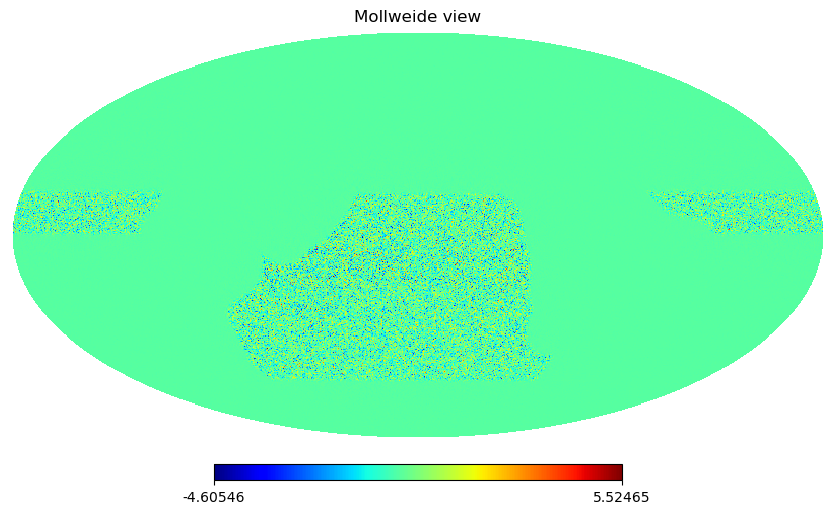

In [92]:
## kappa map in healpy
# Convert any nans to avoid problems later on
kappa_alm = np.nan_to_num(kappa_alm)

# alm to map
map_kappa = hp.alm2map(kappa_alm, nside=2048)

hp.mollview(map_kappa, cmap= "jet")

The cosmic infrared background (CIB) map used here is the 545 GHz Planck CIB map obtained with component separation using the GNILC algorithm. See  **arXiv:1905.00426** for details. The loaded CIB map is expressed in units of MJy $sr^{-1}$, we convert that to $\mu K$ using the appropiate frequency conversion factor.

You can find these maps here [https://irsa.ipac.caltech.edu/data/Planck/release_2/all-sky-maps/foregrounds.html](https://irsa.ipac.caltech.edu/data/Planck/release_2/all-sky-maps/foregrounds.html) and their headers.

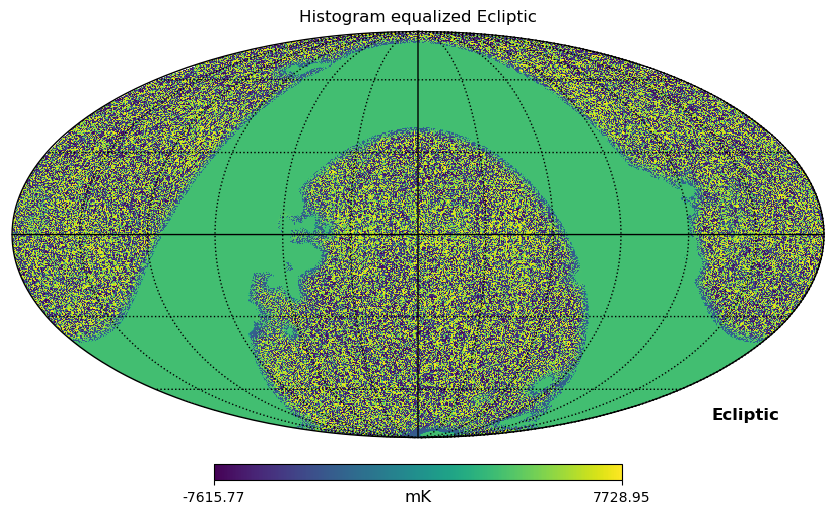

In [93]:
## CIB at 545 GHz

cib_map = hp.read_map("ACT_maps/CIB/COM_CompMap_CIB-GNILC-F545_2048_R2.00.fits")

cib_fact = 1.7508*10**4 # neccesary for units MJy sr-1 to mK

cib_map *= cib_fact

hp.mollview(
    cib_map,
    coord=["G", "E"],
    title="Histogram equalized Ecliptic",
    unit="mK",
    norm="hist")
hp.graticule()

The CIB maps are stored in healpix format in galactic coordinates. To correlate with the ACT lensing maps, we need to convert them to CAR format in equatorial coordinates.

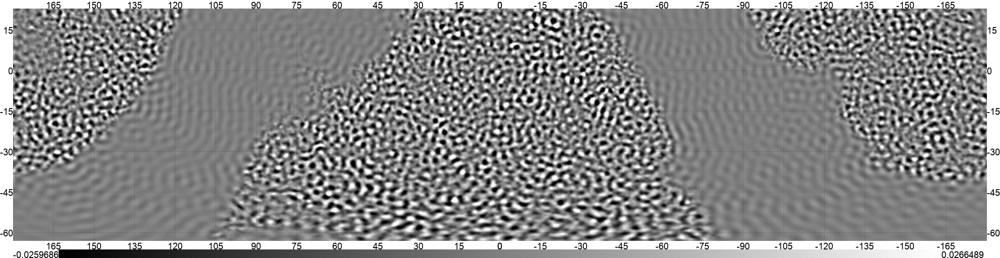

In [94]:
# We apply same mask of convergence map
cib_map = reproject.healpix2map(cib_map, mask.shape, mask.wcs,lmax=3000,rot='gal,equ')

cib_alms = curvedsky.map2alm(cib_map, lmax=3000)

# We apply the same filter the cib_alms as we did to the lensing map above
fcib_alms = hp.almxfl(cib_alms, filter)

# Again we can convert this to map space
filtercib = curvedsky.alm2map(fcib_alms, enmap.empty(mask.shape, mask.wcs))

## Plot
plot = enplot.get_plots(filtercib, downgrade=10, colorbar=True, ticks=15, color='gray')
enplot.show(plot, method="ipython")

We can make the correspondence between the above two maps more apparent by overlying the CIB as contours on top of the lensing map. First lets normalize the CIB so that the values are between 0 and 1.

In [ ]:
## Normalize CIB map

# scikit-learn Machine learning in python more info here: https://scikit-learn.org/stable/
from sklearn import preprocessing as p

min_max_scaler = p.MinMaxScaler()
normalizedData = min_max_scaler.fit_transform(filtercib)
downgrade_factor = 5

normalizedData = enmap.ndmap(normalizedData, mask.wcs)

Next we plot the normalized CIB as contours, with high intensity regions in red and low intensity regions in blue. The lensing map is plotted in black and white.

/home/jorge/.local/lib/python3.10/site-packages/pixell/array_ops.py:15: RuntimeWarning: invalid value encountered in cast
  omap = imap.astype(np.int32)*0


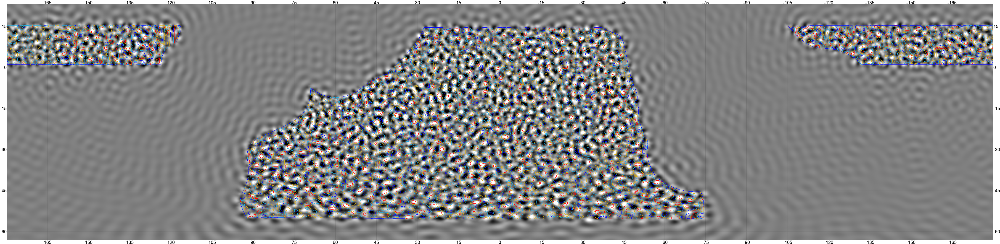

In [ ]:
#lensing map
p1 = enplot.plot(frmap, layers=True, ticks=15, downgrade=downgrade_factor, font_size=20, color='gray')

mask = np.piecewise(mask, [mask>=0.9,mask<0.5], [1, 0])

# apply mask to normalize CIB map
p2 = enplot.plot(normalizedData*mask, layers=True, contours="0.2", contour_width=1,
                 contour_color="1.:FF0000,0.9:e84e0c,0.8:e8730c,0.7:d9a509,0.6:d6c122,0.5:faff66,0.4:66ffa8,0.3:0083FE,0.2:5175ed,0.1:0400FE",
                 ticks=1, downgrade=downgrade_factor, font_size=20, mask=0)

# overlap lensing map and cib contours
p1 += [a for a in p2 if "cont" in a.name]
img = enplot.merge_images([a.img for a in p1])

# We can now plot the contours of each map and look at the correlation by eye.
enplot.show(img, method="ipython")

Zoom in to see a smaller patch

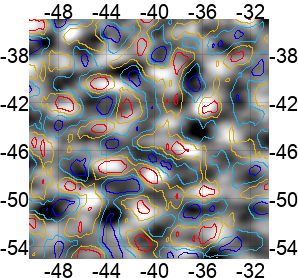

In [98]:
# [[decfrom, rafrom], [[decto, rato]]
dec, ra = np.deg2rad(np.array((-45, -40.5)))
width = np.deg2rad(20)
box = np.array([[dec - width/2., ra - width/2.], [dec + width/2., ra + width/2.]])
stamp = frmap.submap(box)
mask_stamp = mask.submap(box)
normalizedData_stamp = normalizedData.submap(box)

p1 = enplot.plot(stamp, layers=True, ticks=4, downgrade=downgrade_factor, font_size=20, color='gray')
mask_stamp[mask_stamp!=1] = 0
p2 = enplot.plot(mask_stamp*normalizedData_stamp, layers=True, contours="0.2", contour_width=1,
                 contour_color="1.:FF0000,0.9:e84e0c,0.8:e8730c,0.7:d9a509,0.6:d6c122,0.5:faff66,0.4:66ffa8,0.3:0083FE,0.2:5175ed,0.1:0400FE",
                 ticks=1, downgrade=downgrade_factor, font_size=20, mask=0)
p1 += [a for a in p2 if "cont" in a.name]
img = enplot.merge_images([a.img for a in p1])
enplot.show(img, method = "ipython")


## $C_\ell^{\kappa^{ACT} \times \, I^{CIB}}$

Let's see the cross-spectra between $\kappa^{ACT} \times I^{CIB, Planck}$. Differences between pseudo-spectra and NaMaster correction [Link](https://github.com/LSSTDESC/NaMaster/tree/master).... 

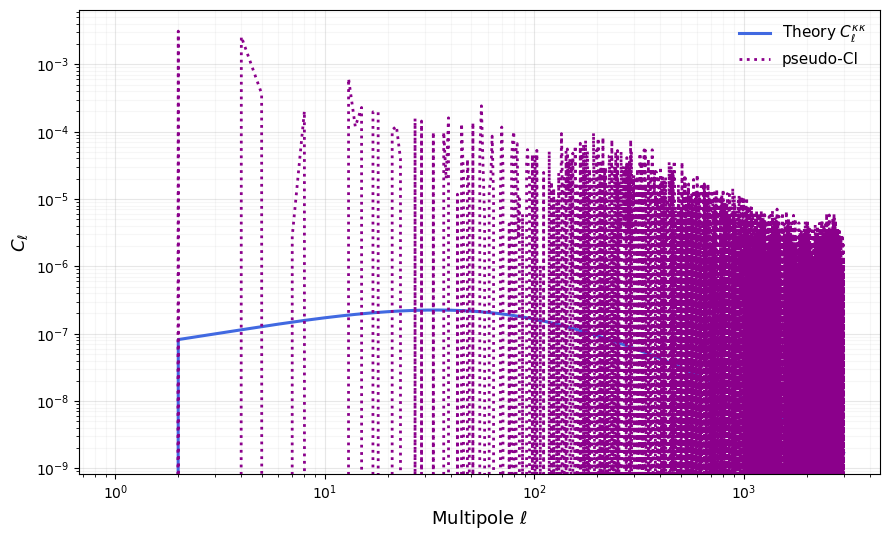

In [ ]:
import pymaster as nmt

lmax = 3000

# (in Equatorial coordinates)
kappa_alm = hp.read_alm("ACT_maps/potencial lensing/dr6_lensing_release/maps/baseline/kappa_alm_data_act_dr6_lensing_v1_baseline.fits")

# Convert any nans to avoid problems later on lmax = 4000
kappa_alm = np.nan_to_num(kappa_alm).astype(np.complex128)

# (galactic coordinates)
cib_map = hp.read_map("ACT_maps/CIB/COM_CompMap_CIB-GNILC-F545_2048_R2.00.fits")

cib_fact = 1.7508*10**4 # neccesary for units MJy sr-1 to mK

cib_map *= cib_fact

cib_alm = hp.map2alm(cib_map, lmax=4000) 

# Rotación: Galácticas -> Ecuatoriales
rot = hp.Rotator(coord=["G", "C"])

cib_alm_equ = rot.rotate_alm(cib_alm.copy(), lmax=4000)

## cross-spectra \kappa_ACT x cib_Planck

# pseudo spectra
pseudo_cl_cross = hp.alm2cl(alms1=kappa_alm, alms2=cib_alm, lmax=4000, lmax_out=lmax)

# NaMaster






## Plots
ell = np.arange(lmax + 1)

plt.figure(figsize=(9, 5.5))

# Espectro teórico
plt.plot(ell, theory_cl_kk[:lmax+1], color="royalblue", linewidth=2.2, label=r"Theory $C_\ell^{\kappa\kappa}$")

# Espectro de pseudo-cl 
plt.plot(ell, pseudo_cl_cross, color="darkmagenta", linewidth=2, linestyle="dotted", label=r"pseudo-Cl")

# Espectro de Namaster
# plt.plot( ell_0, Nl_kk, color="darkorange", linewidth=2, linestyle="--", label=r"Noise $N_\ell^{\kappa\kappa}$")

# Escala logarítmica en ambos ejes
plt.xscale("log")
plt.yscale("log")

# Línea de referencia en ell = 500
# plt.axvline( x=500, color="gray", linestyle=":", linewidth=1.5, alpha=0.8)

plt.xlabel(r"Multipole $\ell$", fontsize=13)
plt.ylabel(r"$C_\ell$", fontsize=13)

# Cuadrícula suave
plt.grid(True, which="major", alpha=0.3)
plt.grid(True, which="minor", alpha=0.1)

plt.legend(fontsize=11, frameon=False)

# Mejorar distribución
plt.tight_layout()

plt.show()



In [ ]:
### PLOTEAR MAPAS BARBARA:

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

mpl.rcParams['font.family']       = 'serif'
mpl.rcParams['font.serif']        = ['DejaVu Serif', 'Times New Roman', 'serif']
mpl.rcParams['mathtext.fontset']  = 'dejavuserif'   
mpl.rcParams['text.usetex']       = False            

mpl.rcParams['font.size']         = 14
mpl.rcParams['axes.titlesize']    = 15
mpl.rcParams['axes.labelsize']    = 14
mpl.rcParams['xtick.labelsize']   = 12
mpl.rcParams['ytick.labelsize']   = 12
mpl.rcParams['legend.fontsize']   = 12
mpl.rcParams['legend.title_fontsize'] = 13


mpl.rcParams['figure.dpi'] = 120
mpl.rcParams['savefig.dpi']       = 600         
mpl.rcParams['savefig.bbox']      = 'tight'
mpl.rcParams['savefig.format']    = 'pdf'       

mpl.rcParams['axes.spines.top']   = True
mpl.rcParams['axes.spines.right'] = True
mpl.rcParams['axes.edgecolor']    = 'black'
mpl.rcParams['axes.linewidth']    = 1.2  


N_colores = 8                                      
cmap      = mpl.colormaps['rainbow']               
colores   = [cmap(i / (N_colores - 1)) for i in range(N_colores)]
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=colores)

mpl.rcParams['axes.grid']         = True
mpl.rcParams['grid.color']        = '0.85'
mpl.rcParams['grid.linestyle']    = '--'
mpl.rcParams['grid.linewidth']    = 0.6
mpl.rcParams['grid.alpha']        = 0.7

mpl.rcParams['xtick.direction']   = 'in'
mpl.rcParams['ytick.direction']   = 'in'
mpl.rcParams['xtick.major.size']  = 5
mpl.rcParams['ytick.major.size']  = 5
mpl.rcParams['xtick.minor.size']  = 3
mpl.rcParams['ytick.minor.size']  = 3
mpl.rcParams['xtick.major.width'] = 1.0
mpl.rcParams['ytick.major.width'] = 1.0
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

mpl.rcParams['lines.linewidth']   = 2.0
mpl.rcParams['lines.markersize']  = 6

mpl.rcParams['legend.frameon']    = True
mpl.rcParams['legend.framealpha'] = 0.85
mpl.rcParams['legend.edgecolor']  = '0.8'
mpl.rcParams['legend.fancybox']   = False

mpl.rcParams['image.cmap']        = 'rainbow'

hp.mollview(mapa_temperatura, min=-400, max=400, cmap='coolwarm', unit=UNIT, title='ACT+PLANCK') #acá están marrcados por 0


## POR HACER

- El mapa coadded maps tiene I Q y U, faltaria hacer la combinacion como el paper. Sin embargo el de nilc solo tiene mapa de temperatura asi que no me sirve para QE.
- Ver Bias-hardened method
- ver catalogo de galaxias y sistematicos
- hacer delensing con datos reales como Emilie tratar de copiar plots
- Ver de donde saca Emilie el mapa de los modos E de ACT para hacer el Template B modes.